# VERDE - Do the Final Models Work on Real Photos?
### Smart Recycling and Waste Segregation Assistant - the three best models from the ablation notebooks, checked on real-world photos

**Question:** The three final models selected in the training-strategy ablation notebooks (EfficientNet-B0, MobileNetV3-Large, ResNet-50) score 93 to 95% on the dataset test set. How well do they do on real photos taken by us, and does averaging the three help?

**Answer: Poorly:** 42-54% on real photos against 93-95% on the dataset, and averaging the three cuts the confident wrong answers (to 2) but does not raise accuracy.

**Inputs to attach:** Add Input -> Notebook Output -> (1) the three ablation notebooks: `verde-efficientnet-b0-training-strategy-ablation`, `verde-mobilenetv3-large-training-strategy-ablation`, `verde-resnet-50-training-strategy-ablation`; (2) your real-photo dataset (a Kaggle dataset); (3) optional: `verde-data-analysis-2-0`, only needed for Section 4. **Settings:** GPU optional (CPU is enough), Internet off is fine. **Run time:** about 2 minutes.

<a id="section-1"></a>
## Section 1: Aim and Method

**Goal:** State what is checked and how, so the result can be trusted and explained.

**The models** are the best model of each ablation notebook, selected there with the **validation** set only (so none of the real photos had any part in choosing them). The notebook reads each model's name, training configuration and seed from its file `verde_final_<network>.pth`. A fourth column, the **average of the three**, adds the three models' probabilities (the multi-backbone fusion result).

**How a photo is scored** (the app says "not sure" below 60% confidence):

| Outcome | Meaning | What the user sees |
|---|---|---|
| Correct | Right class, confidence 60% or more | The right bin |
| Right but not sure | Right class, confidence below 60% | "Not sure - check locally" |
| Not sure (wrong) | Wrong class, confidence below 60% | "Not sure - check locally" (harmless) |
| **Confidently wrong** | Wrong class, confidence 60% or more | **The wrong bin, with no warning** |

Confidently wrong answers are the worst outcome, because the confidence rule does not protect against them. A good model has high accuracy and few of them.

**Preprocessing matches the Pi and the app:** fix the phone rotation (EXIF), centre-crop to a square, resize to 224x224 (LANCZOS), normalise with the ImageNet mean and standard deviation. The item must therefore be near the centre of the photo, because the edges are cut off.

**Be careful with small numbers.** With about 24 photos, one photo is about 4 points of accuracy. Treat the result as a pilot check, not a score. The dataset score in Section 4 is measured on 2,164 images and is far more precise.

**Terms used in this notebook:**

| Term | Plain meaning |
|---|---|
| Final model | The best model of an ablation notebook, selected on validation |
| Top-3 accuracy | The right class is among the model's three best guesses |
| Confidence | The model's highest probability, from 0 to 100% |
| Dataset gap | Dataset accuracy minus real-photo accuracy: how much the models lose on our own photos |
| Average of the three | The three models' probabilities averaged (late fusion) |

<a id="section-2"></a>
## Section 2: Setup: Models and Photos

**Goal:** Load the three final models and the real photos.

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image, ImageOps
from tqdm import tqdm

import torch
import torch.nn as nn
import torchvision.models as tvm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

INPUT, OUT = Path("/kaggle/input"), Path("/kaggle/working")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

B0, MN, RN = "effnet_b0", "v3_large", "resnet50"
ARCHS = {B0: tvm.efficientnet_b0, MN: tvm.mobilenet_v3_large, RN: tvm.resnet50}
NAMES = {B0: "EfficientNet-B0", MN: "MobileNetV3-Large", RN: "ResNet-50"}

def build_model(arch, n_classes):
    """A network with an n_classes output layer and no pretrained weights."""
    net = ARCHS[arch](weights=None)
    if hasattr(net, "fc"):                       # ResNet
        net.fc = nn.Linear(net.fc.in_features, n_classes)
    else:                                        # MobileNet / EfficientNet
        last = max(i for i, m in enumerate(net.classifier) if isinstance(m, nn.Linear))
        net.classifier[last] = nn.Linear(net.classifier[last].in_features, n_classes)
    return net

files = {}
for f in sorted(INPUT.rglob("verde_final_*.pth")):
    ck = torch.load(f, map_location="cpu")
    files.setdefault(ck["arch"], []).append((f, ck))

nets, info, class_names = {}, {}, None
for arch in ARCHS:
    assert arch in files, f"verde_final file for {NAMES[arch]} not found: attach its ablation notebook output"
    if len(files[arch]) > 1:
        print(f"WARNING: {len(files[arch])} final files for {NAMES[arch]}; using {files[arch][0][0]}")
    f, ck = files[arch][0]
    if class_names is None:
        class_names = ck["class_names"]
    assert ck["class_names"] == class_names, "class order differs between models"
    net = build_model(arch, len(class_names))
    net.load_state_dict(ck["model_state"])
    nets[arch] = net.to(device).eval()
    info[arch] = {"config": ck["config"], "seed": ck["seed"], "val F1": ck["val_f1"],
                  "size (MB)": sum(p.numel() for p in net.parameters()) * 4 / 1e6}

class_to_idx = {c: i for i, c in enumerate(class_names)}
display(pd.DataFrame(info).T.rename(index=NAMES).round(3))

,config,seed,val F1,size (MB)
EfficientNet-B0,T3,7,0.940412,16.071184
MobileNetV3-Large,T4,7,0.933906,16.84912
ResNet-50,T3,42,0.924589,94.097696


**Finding:** The selected models are EfficientNet-B0 (T3, seed 7, validation F1 0.940), MobileNetV3-Large (T4, seed 7, 0.934) and ResNet-50 (T3, seed 42, 0.925), all chosen on validation only. B0 and MobileNet are about 16-17 MB; ResNet-50 is 94 MB, nearly 6 times larger.

24 photos: 24 scored, 0 without a class prefix (shown only)
food_garden    2
general        7
glass          1
metal          3
paper_card     3
plastic        2
special        1
textile        5


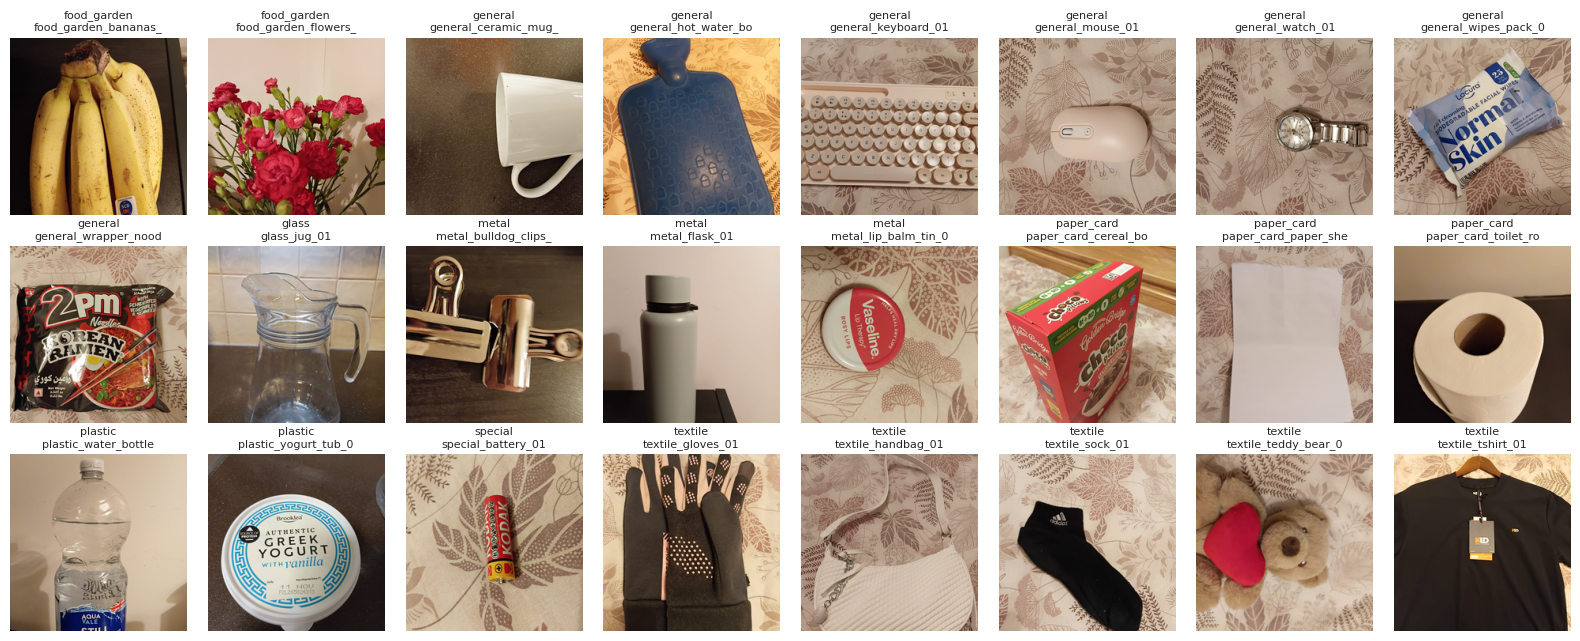

In [2]:
# WHAT: Find the real photos, read each photo's class from the start of its file name, and
#       prepare every photo as a 224x224 square.
# WHY:  The class of a photo must come from you, not from a model. A file name such as
#       plastic_bottle_01.jpg means class "plastic". Class names with an underscore
#       (food_garden, paper_card) are matched as a whole. Photos with no class prefix are
#       kept, but only shown, not scored.
# HOW:  Every image under /kaggle/input is considered, except the data-analysis images and
#       the charts saved inside the attached notebook outputs. Preprocessing is the same as
#       on the Pi and in the app. y_photo is -1 for a photo with no class prefix.
# ------------------------------------------------------------------------------------

ROOT = Path("/kaggle/input/notebooks/tanveerdalal/verde-data-analysis-2-0")
skip_dirs = [ROOT] + [f.parent for fl in files.values() for f, _ in fl]
EXTS = {".jpg", ".jpeg", ".png", ".webp"}

def is_photo(p):
    return (p.suffix.lower() in EXTS and "verde_std" not in p.parts
            and not any(p.is_relative_to(d) for d in skip_dirs))

def label_of(path):
    stem = path.stem.lower()
    for c in sorted(class_names, key=len, reverse=True):
        if stem.startswith(c + "_"):
            return c
    return None

def square(path):
    """Same steps as the Pi and the app: rotation fix, centre square, 224x224."""
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return img.crop((left, top, left + s, top + s)).resize((224, 224), Image.LANCZOS)

MEAN_T = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD_T = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_batch(imgs):
    """A list of 224x224 PIL images -> normalised tensor [n, 3, 224, 224] on the device."""
    x = torch.from_numpy(np.stack([np.array(i) for i in imgs])).permute(0, 3, 1, 2)
    return (x.float().to(device) / 255 - MEAN_T) / STD_T

paths = sorted(p for p in INPUT.rglob("*") if is_photo(p))
assert paths, "No photos found: attach your real-photo dataset"
labels = [label_of(p) for p in paths]
photo_names = [p.name for p in paths]
y_photo = np.array([class_to_idx[c] if c else -1 for c in labels])
thumbs = [square(p) for p in paths]
scored = y_photo >= 0

print(f"{len(paths)} photos: {scored.sum()} scored, {(~scored).sum()} without a class prefix (shown only)")
if scored.any():
    print(pd.Series([c for c in labels if c]).value_counts().reindex(class_names).fillna(0).astype(int).to_string())
if (~scored).any():
    print("Not scored:", [n for n, s in zip(photo_names, scored) if not s][:10])

n_show = min(len(thumbs), 24)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), range(n_show)):
    ax.imshow(thumbs[i])
    ax.set_title(f"{labels[i] or '?'}\n{paths[i].stem[:20]}", fontsize=8)
plt.tight_layout(); plt.show()

**Finding:** There are 24 photos: general 7, textile 5, metal 3, paper_card 3, food_garden 2, plastic 2, glass 1, special 1. Each label matches its photo, and the item is near the centre in almost all of them; the square crop cuts the edges of the keyboard and the noodle wrapper. Five labels were judgement calls made before scoring (handbag, watch, flask, lip balm tin, teddy bear), so any model's score could move by one to three photos if they were labelled differently.

<a id="section-3"></a>
## Section 3: Predictions

**Goal:** Run each final model on every photo, and add the average of the three.

In [3]:
# WHAT: Compute each model's class probabilities for every photo, and the average of the three.
# WHY:  Probabilities (not only the top answer) give the confidence, the top-3 guesses and the
#       "not sure" decision. The average is the multi-backbone fusion result, shown next to
#       the single models so the two can be compared on the same photos.
# HOW:  Softmax of each model's outputs, one row per photo. The app's threshold is 60%.
# ------------------------------------------------------------------------------------

THRESHOLD = 0.60
ORDER = [B0, MN, RN, "average"]
LABELS = {**NAMES, "average": "Average of the three"}

batch = to_batch(thumbs)
P = {}
with torch.no_grad():
    for arch, net in nets.items():
        P[arch] = torch.softmax(net(batch), 1).cpu().numpy()
P["average"] = np.mean([P[a] for a in (B0, MN, RN)], axis=0)
print(f"Predicted {len(paths)} photos with {len(nets)} models and their average")

Predicted 24 photos with 3 models and their average


**Finding:** All three models and their average ran on all 24 photos.

<a id="section-4"></a>
## Section 4: Dataset Score for Comparison

**Goal:** Measure the same three models on the dataset test set, so the loss on real photos can be put next to the dataset score.

In [4]:
# WHAT: Run the three final models and their average on the 2,164 dataset test images, and keep
#       the overall accuracy and the accuracy on RealWaste (real floor photos).
# WHY:  The project's main finding is a domain gap: models score about 94% on the dataset but
#       fail on real items. This puts a number on that gap for the final models. The test
#       images were never used for training or for choosing these models. This section is
#       skipped if the data-analysis notebook output is not attached.
# HOW:  Dataset images are already 224x224. The same normalisation and batches as Section 3.
# ------------------------------------------------------------------------------------

ds_acc, ds_rw = {}, {}
if (ROOT / "final_dataset_std.csv").exists():
    frame = pd.read_csv(ROOT / "final_dataset_std.csv")
    frame = frame[frame["split"] == "test"].reset_index(drop=True)
    y_ds = frame["final_class"].map(class_to_idx).to_numpy()
    img_paths = (str(ROOT / "verde_std") + "/" + frame["rel_path"]).tolist()
    probs = {k: [] for k in ORDER}
    with torch.no_grad():
        for i in tqdm(range(0, len(img_paths), 128), leave=False):
            imgs = [Image.open(p).convert("RGB") for p in img_paths[i:i + 128]]
            x = to_batch(imgs)
            batch_p = {a: torch.softmax(nets[a](x), 1).cpu().numpy() for a in nets}
            batch_p["average"] = np.mean([batch_p[a] for a in (B0, MN, RN)], axis=0)
            for k in ORDER:
                probs[k].append(batch_p[k])
    for k in ORDER:
        ok = np.concatenate(probs[k]).argmax(1) == y_ds
        ds_acc[k], ds_rw[k] = ok.mean(), ok[(frame["src"] == "RealWaste").to_numpy()].mean()
    display(pd.DataFrame({"test accuracy": ds_acc, "RealWaste accuracy": ds_rw}).rename(index=LABELS).round(3))
else:
    print("Data-analysis output not attached: dataset comparison skipped.")

,test accuracy,RealWaste accuracy
EfficientNet-B0,0.945,0.936
MobileNetV3-Large,0.930,0.916
ResNet-50,0.932,0.910
Average of the three,0.948,0.940


**Finding:** On the dataset test set the models score 94.5% (B0), 93.0% (MobileNet) and 93.2% (ResNet-50); the average scores 94.8%. On RealWaste images alone they score 93.6%, 91.6% and 91.0%; the average scores 94.0%. These are the numbers the real-photo results are compared with.

<a id="section-5"></a>
## Section 5: Results on Real Photos

**Goal:** Score every model on the labelled real photos and count the dangerous case, confident wrong answers.

24 scored photos; one photo = 4.2%


,dataset test acc,photo top-1 acc,photo top-3 acc,app correct,not sure,confident wrong,gap to dataset
model,,,,,,,
EfficientNet-B0,0.945,0.500,0.750,0.458,0.292,6,0.445
MobileNetV3-Large,0.930,0.458,0.750,0.375,0.500,3,0.471
ResNet-50,0.932,0.417,0.667,0.375,0.208,10,0.515
Average of the three,0.948,0.542,0.750,0.292,0.625,2,0.406


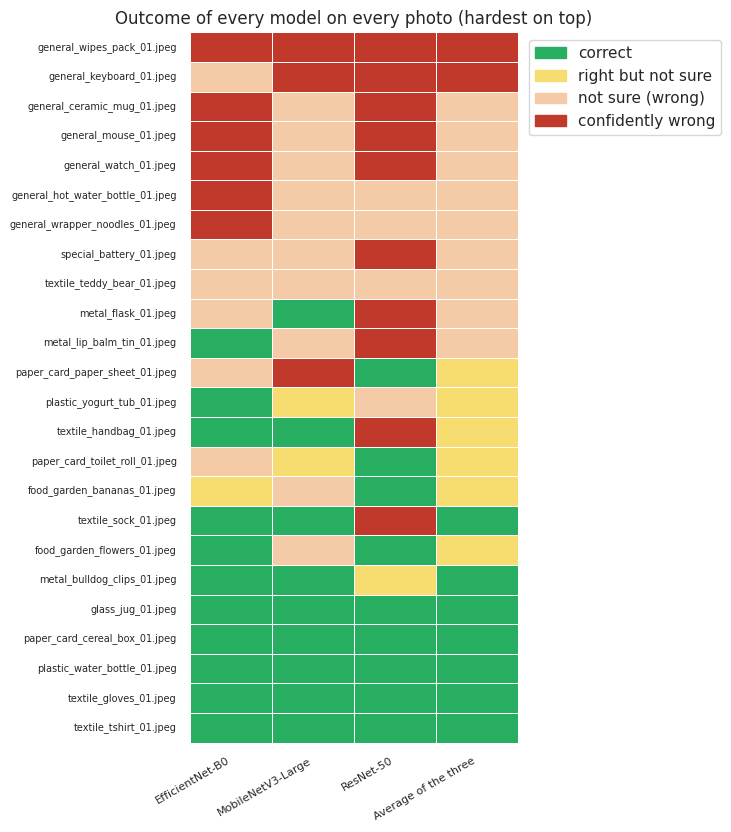

In [5]:
# WHAT: Build one results table (a row per model) and a photo-by-model outcome grid.
# WHY:  Accuracy alone hides the dangerous case. The table counts answers that are wrong but
#       confident (60% or more), which the app would show with no warning. "app correct" is
#       the share of photos the app would answer AND get right. The gap to the dataset score
#       shows how much each model loses on our own photos.
# HOW:  Only labelled photos are scored. Top-1 uses the highest probability; top-3 checks the
#       three highest. The grid colours each photo for each model with the four outcomes
#       explained in Section 1; hardest photos are on top.
# ------------------------------------------------------------------------------------

HAVE_LABELS = bool(scored.any())
if not HAVE_LABELS:
    print("No photo has a class prefix, so nothing can be scored. Rename the files to "
          "class_item_number.jpg (for example plastic_bottle_01.jpg) and run again.")
else:
    y = y_photo[scored]
    rows, codes = [], {}
    for k in ORDER:
        p = P[k][scored]
        pred, conf = p.argmax(1), p.max(1)
        correct, sure = pred == y, conf >= THRESHOLD
        top3 = np.argsort(-p, axis=1)[:, :3]
        # 3 = correct, 2 = right but not sure, 1 = not sure (wrong), 0 = confidently wrong
        codes[LABELS[k]] = np.where(correct & sure, 3, np.where(correct, 2, np.where(~sure, 1, 0)))
        rows.append({"model": LABELS[k],
                     "dataset test acc": ds_acc.get(k, np.nan),
                     "photo top-1 acc": correct.mean(),
                     "photo top-3 acc": np.mean([a in t for a, t in zip(y, top3)]),
                     "app correct": (correct & sure).mean(),
                     "not sure": (~sure).mean(),
                     "confident wrong": int((~correct & sure).sum())})
    results = pd.DataFrame(rows).set_index("model")
    results["gap to dataset"] = results["dataset test acc"] - results["photo top-1 acc"]
    print(f"{len(y)} scored photos; one photo = {1 / len(y):.1%}")
    display(results.round(3))

    names_scored = [n for n, s in zip(photo_names, scored) if s]
    grid = pd.DataFrame(codes, index=names_scored)
    grid = grid.loc[grid.sum(axis=1).sort_values().index]
    colours = ["#c0392b", "#f5cba7", "#f7dc6f", "#27ae60"]
    fig, ax = plt.subplots(figsize=(7.5, max(4, 0.27 * len(grid) + 2)))
    sns.heatmap(grid, cmap=ListedColormap(colours), vmin=-0.5, vmax=3.5, cbar=False,
                linewidths=0.4, linecolor="white", ax=ax)
    ax.set_xlabel(""); ax.set_ylabel("")
    plt.xticks(rotation=30, ha="right", fontsize=8); plt.yticks(fontsize=7)
    ax.legend(handles=[Patch(color=colours[3], label="correct"),
                       Patch(color=colours[2], label="right but not sure"),
                       Patch(color=colours[1], label="not sure (wrong)"),
                       Patch(color=colours[0], label="confidently wrong")],
              loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title("Outcome of every model on every photo (hardest on top)")
    plt.tight_layout()
    plt.savefig(OUT / "real_photo_grid.png", dpi=150, bbox_inches="tight")
    plt.show()

**Finding:** Real-photo accuracy is far below the dataset score. Top-1 is 50.0% for B0, 45.8% for MobileNet, 41.7% for ResNet-50 and 54.2% for the average, a gap of 41-52 points. One photo is 4.2 points, so 50% on 24 photos could be anywhere from about 31% to 69%, still far below 94%. Confident wrong answers (60% or more): ResNet-50 10, B0 6, MobileNet 3, average 2. The average has the highest top-1 (13 photos against 12 for B0), but a one-photo gap is not a difference. Its real benefit is safety: it gives the app's correct answer on only 7 photos (29%) against 11 for B0 (46%), and says "not sure" on 15. ResNet-50 is the worst on top-1, top-3 and confident wrong answers, and is the largest model.

<a id="section-6"></a>
## Section 6: Per-Photo View

**Goal:** See what every model said on every photo, with its top-3 guesses.

,photo,true,EfficientNet-B0,MobileNetV3-Large,ResNet-50,Average of the three,note
0,food_garden_bananas_01.jpeg,food_garden,not sure 60%,not sure 52%,food_garden 63%,not sure 49%,disagree
1,food_garden_flowers_01.jpeg,food_garden,food_garden 76%,not sure 27%,food_garden 74%,not sure 56%,disagree
2,general_ceramic_mug_01.jpeg,general,plastic 65%,not sure 50%,plastic 74%,not sure 51%,disagree
3,general_hot_water_bottle_01.,general,glass 69%,not sure 40%,not sure 40%,not sure 38%,disagree
4,general_keyboard_01.jpeg,general,not sure 54%,paper_card 70%,paper_card 89%,paper_card 71%,WRONG!
5,general_mouse_01.jpeg,general,metal 74%,not sure 31%,paper_card 70%,not sure 27%,disagree
6,general_watch_01.jpeg,general,metal 94%,not sure 41%,paper_card 67%,not sure 48%,disagree
7,general_wipes_pack_01.jpeg,general,paper_card 87%,paper_card 76%,paper_card 92%,paper_card 85%,WRONG!
8,general_wrapper_noodles_01.j,general,textile 67%,not sure 38%,not sure 49%,not sure 37%,disagree
9,glass_jug_01.jpeg,glass,glass 87%,glass 88%,glass 89%,glass 88%,


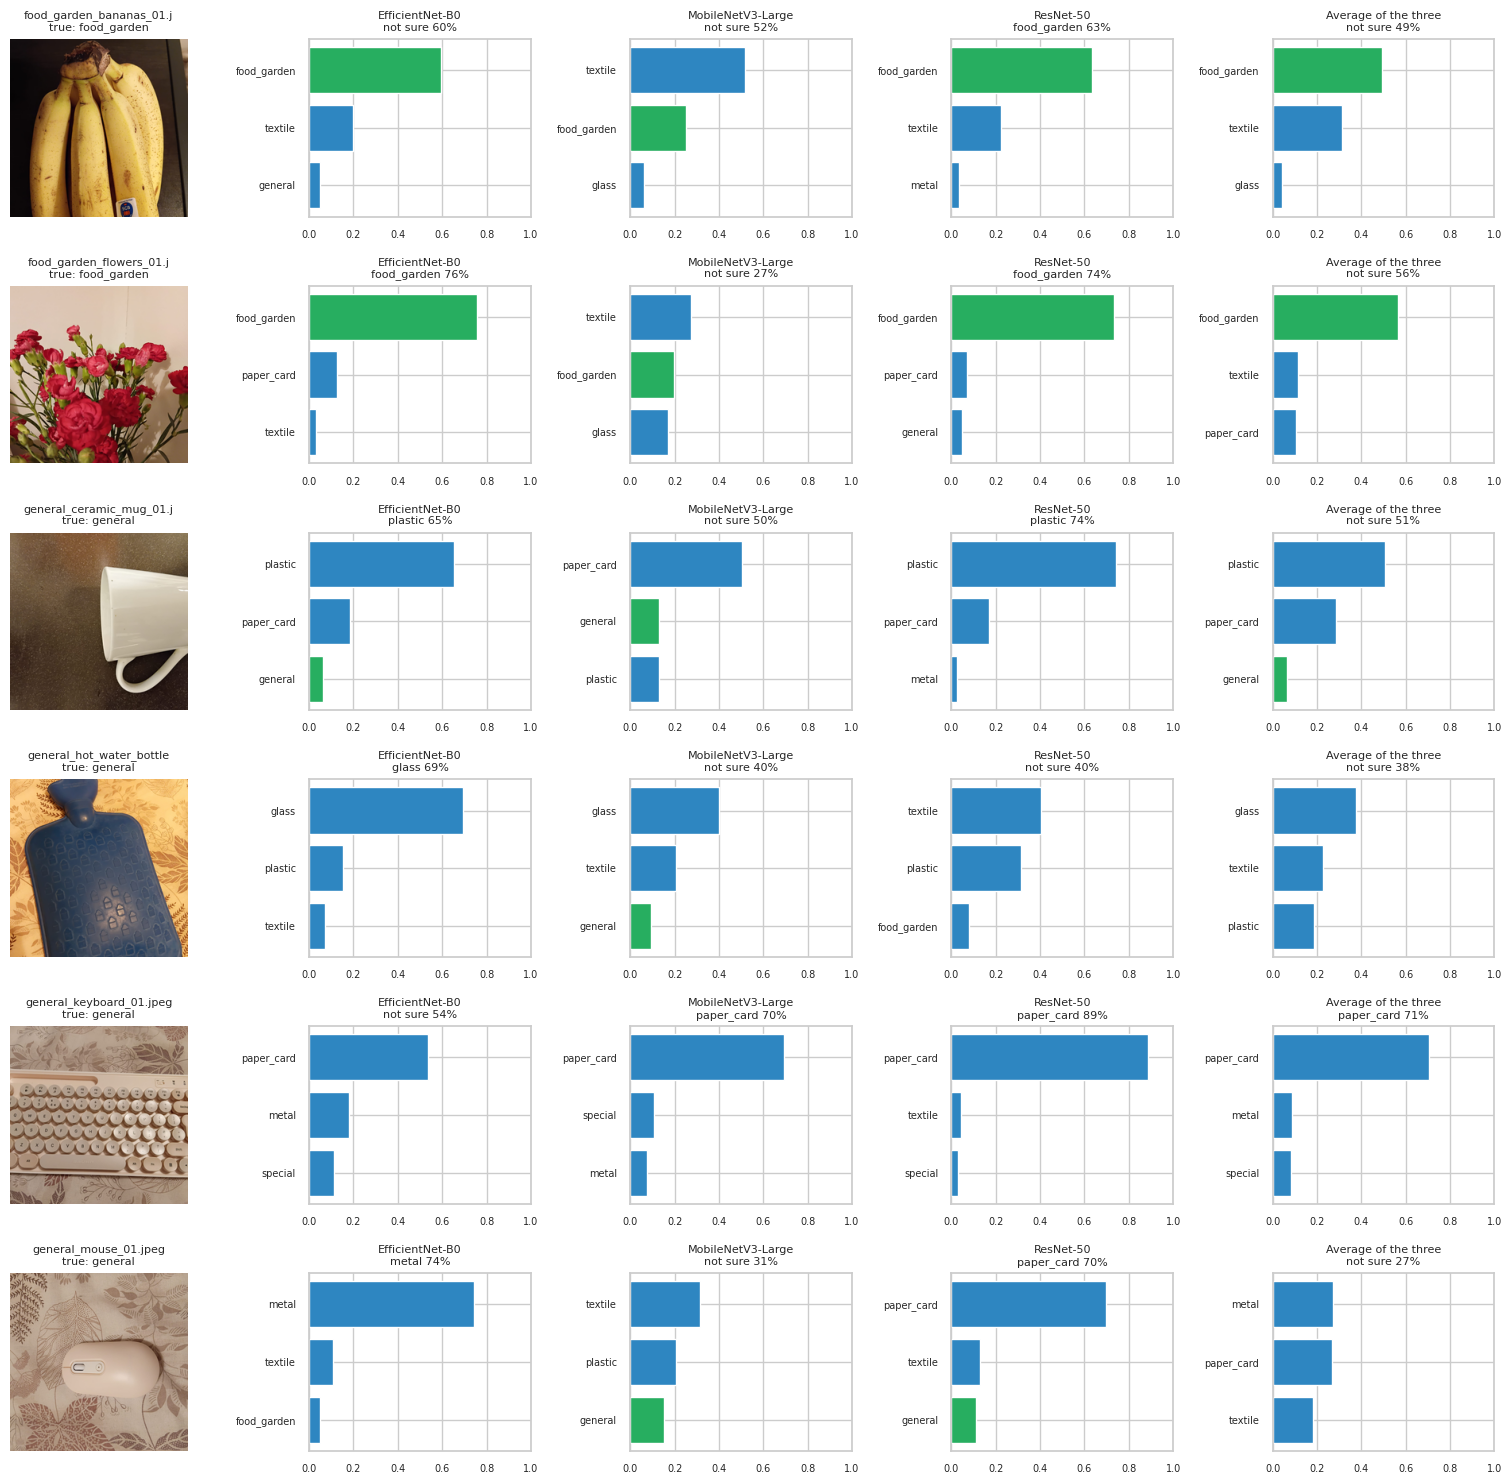

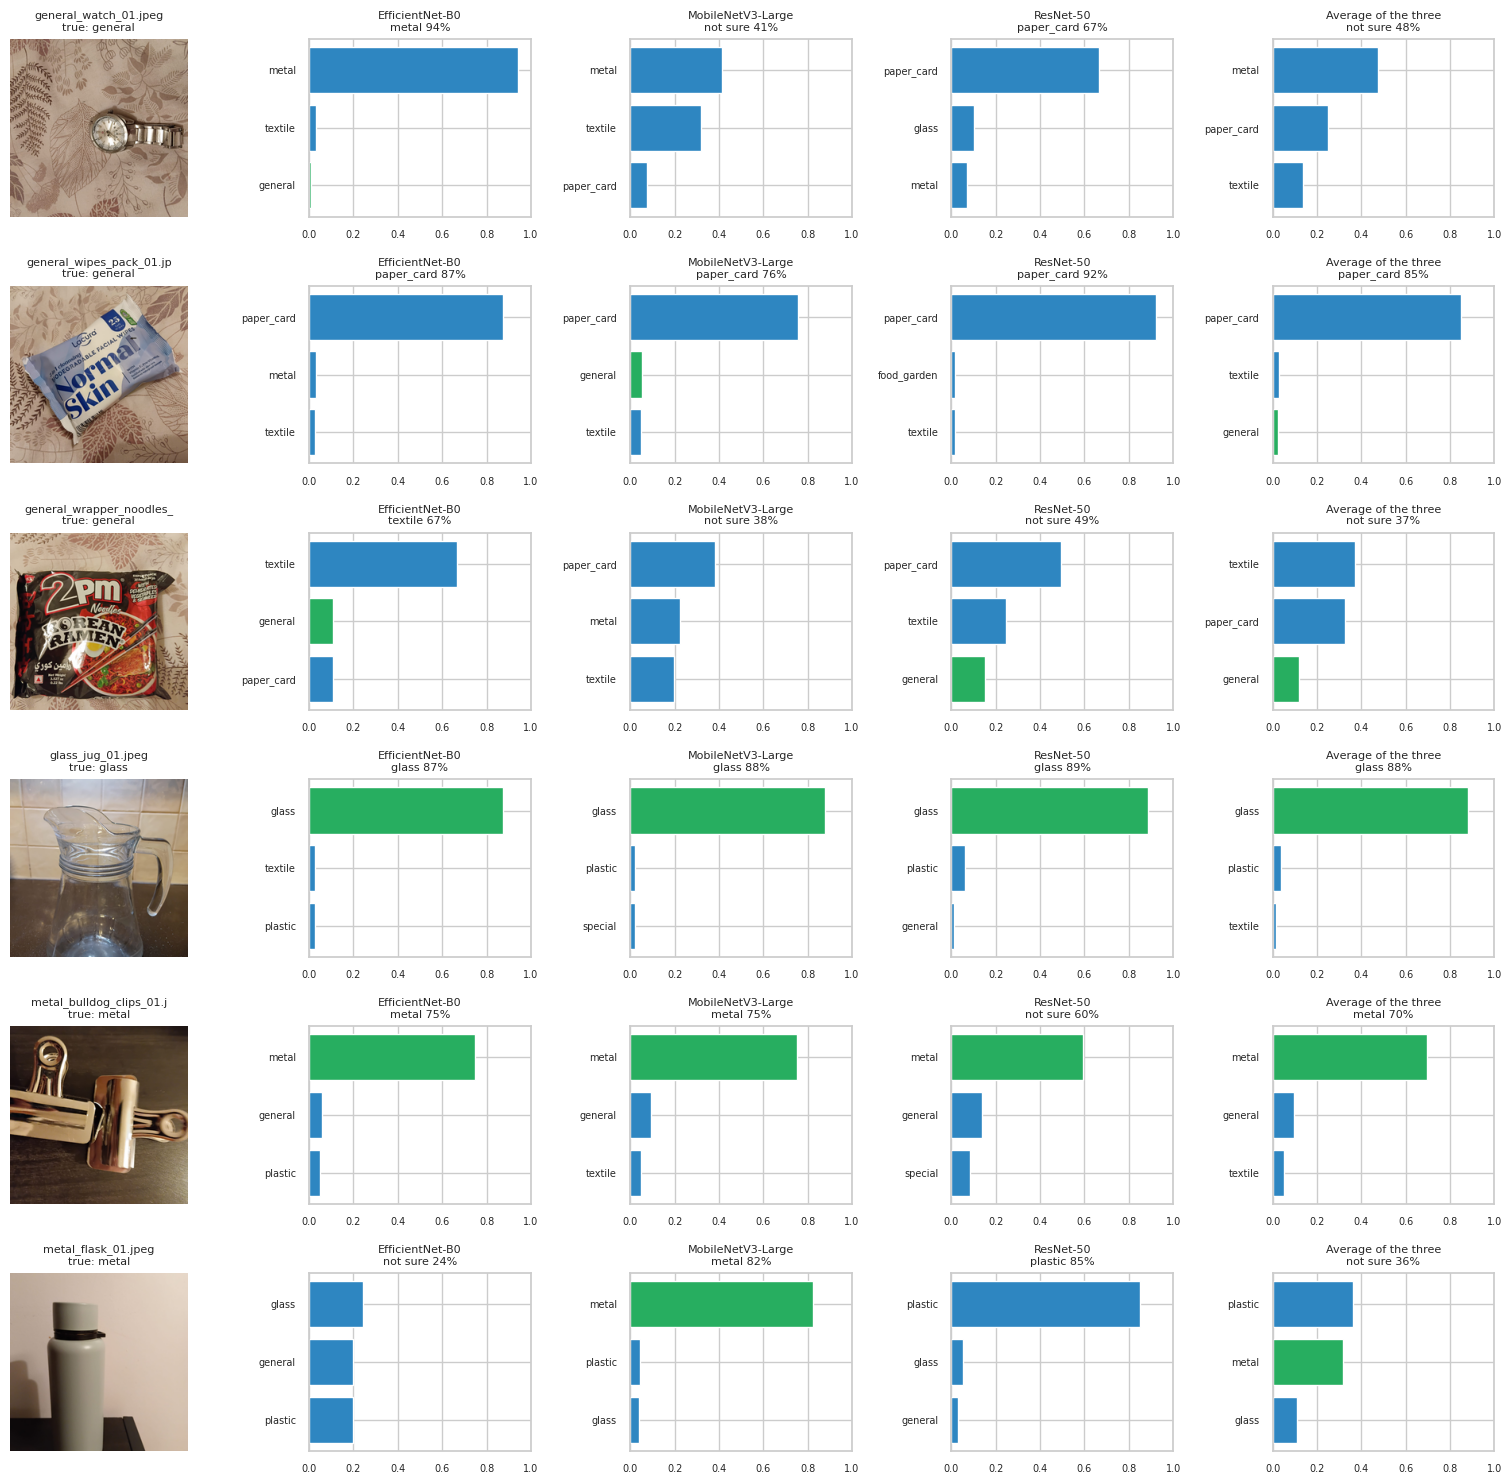

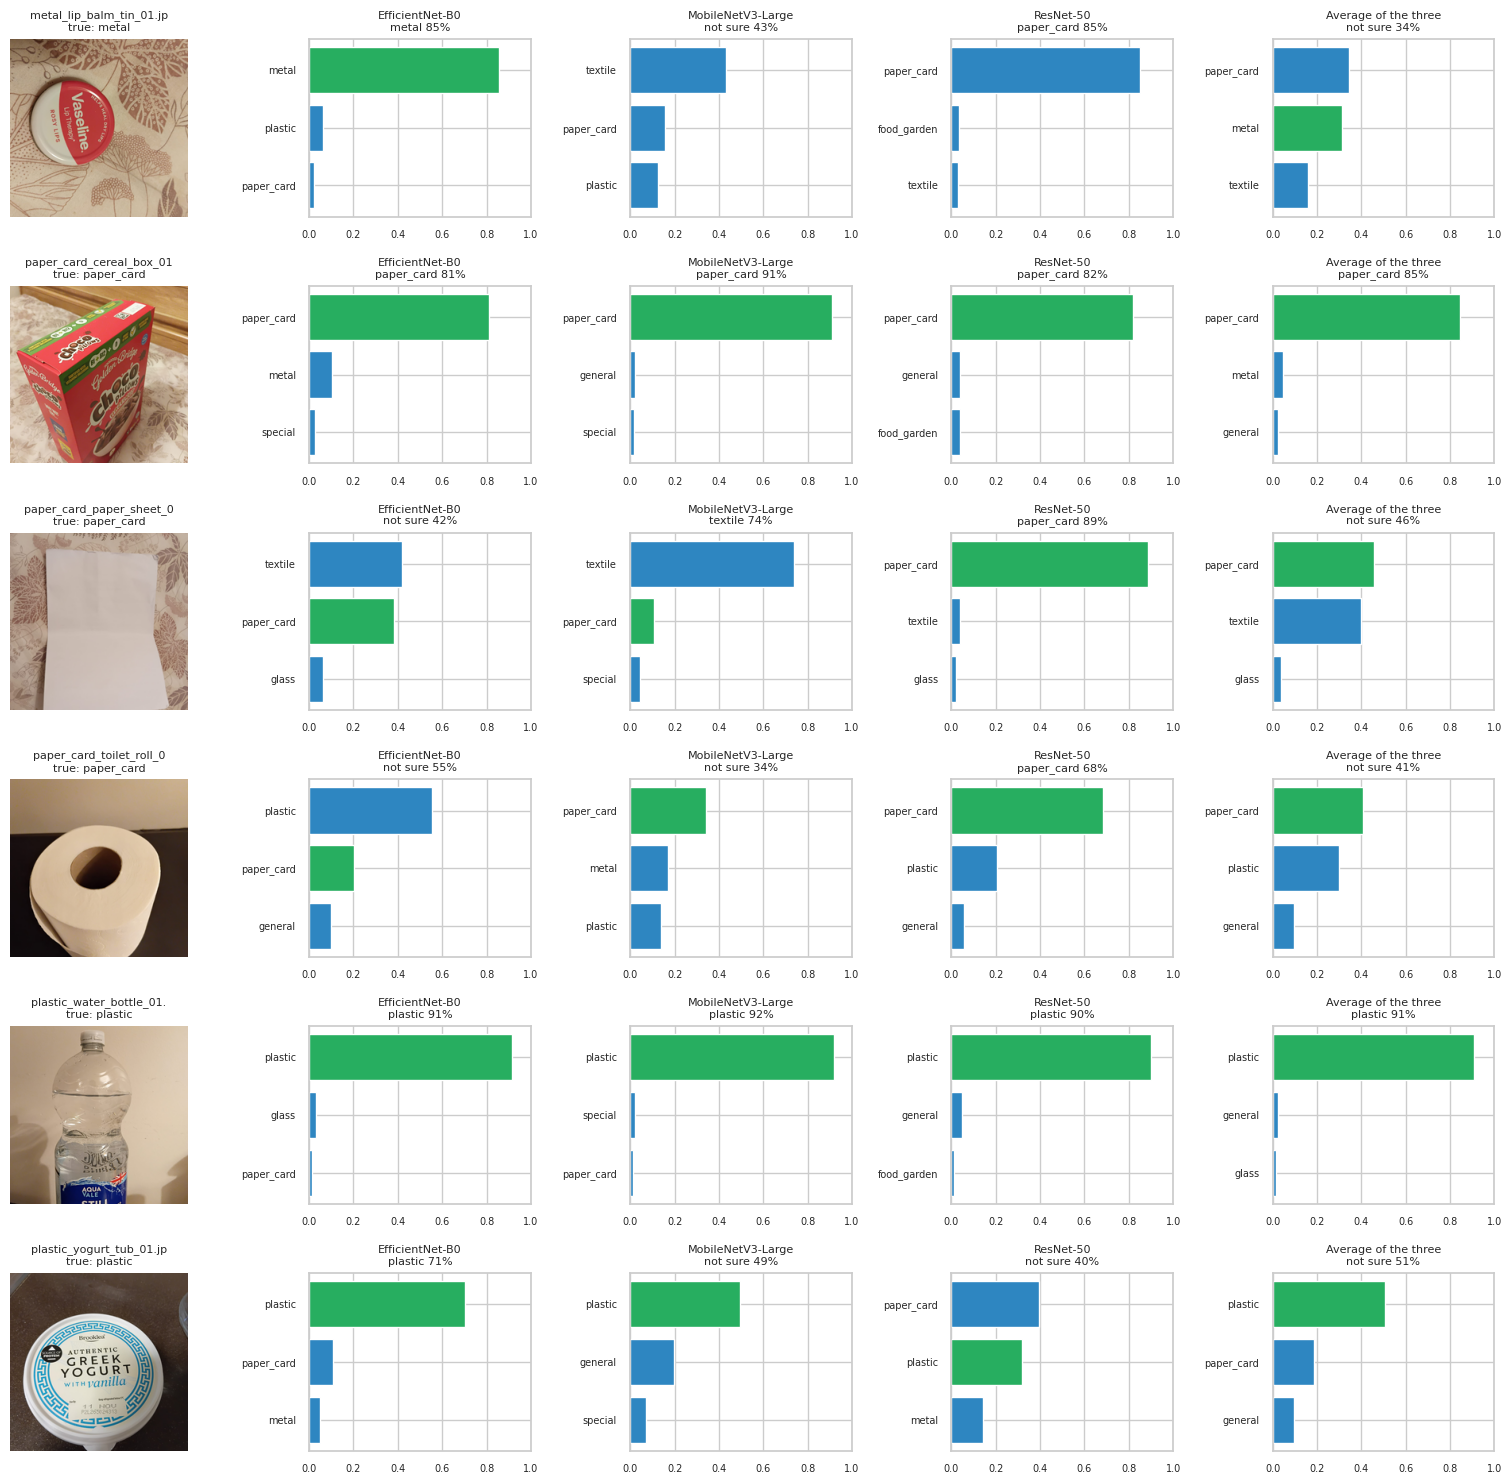

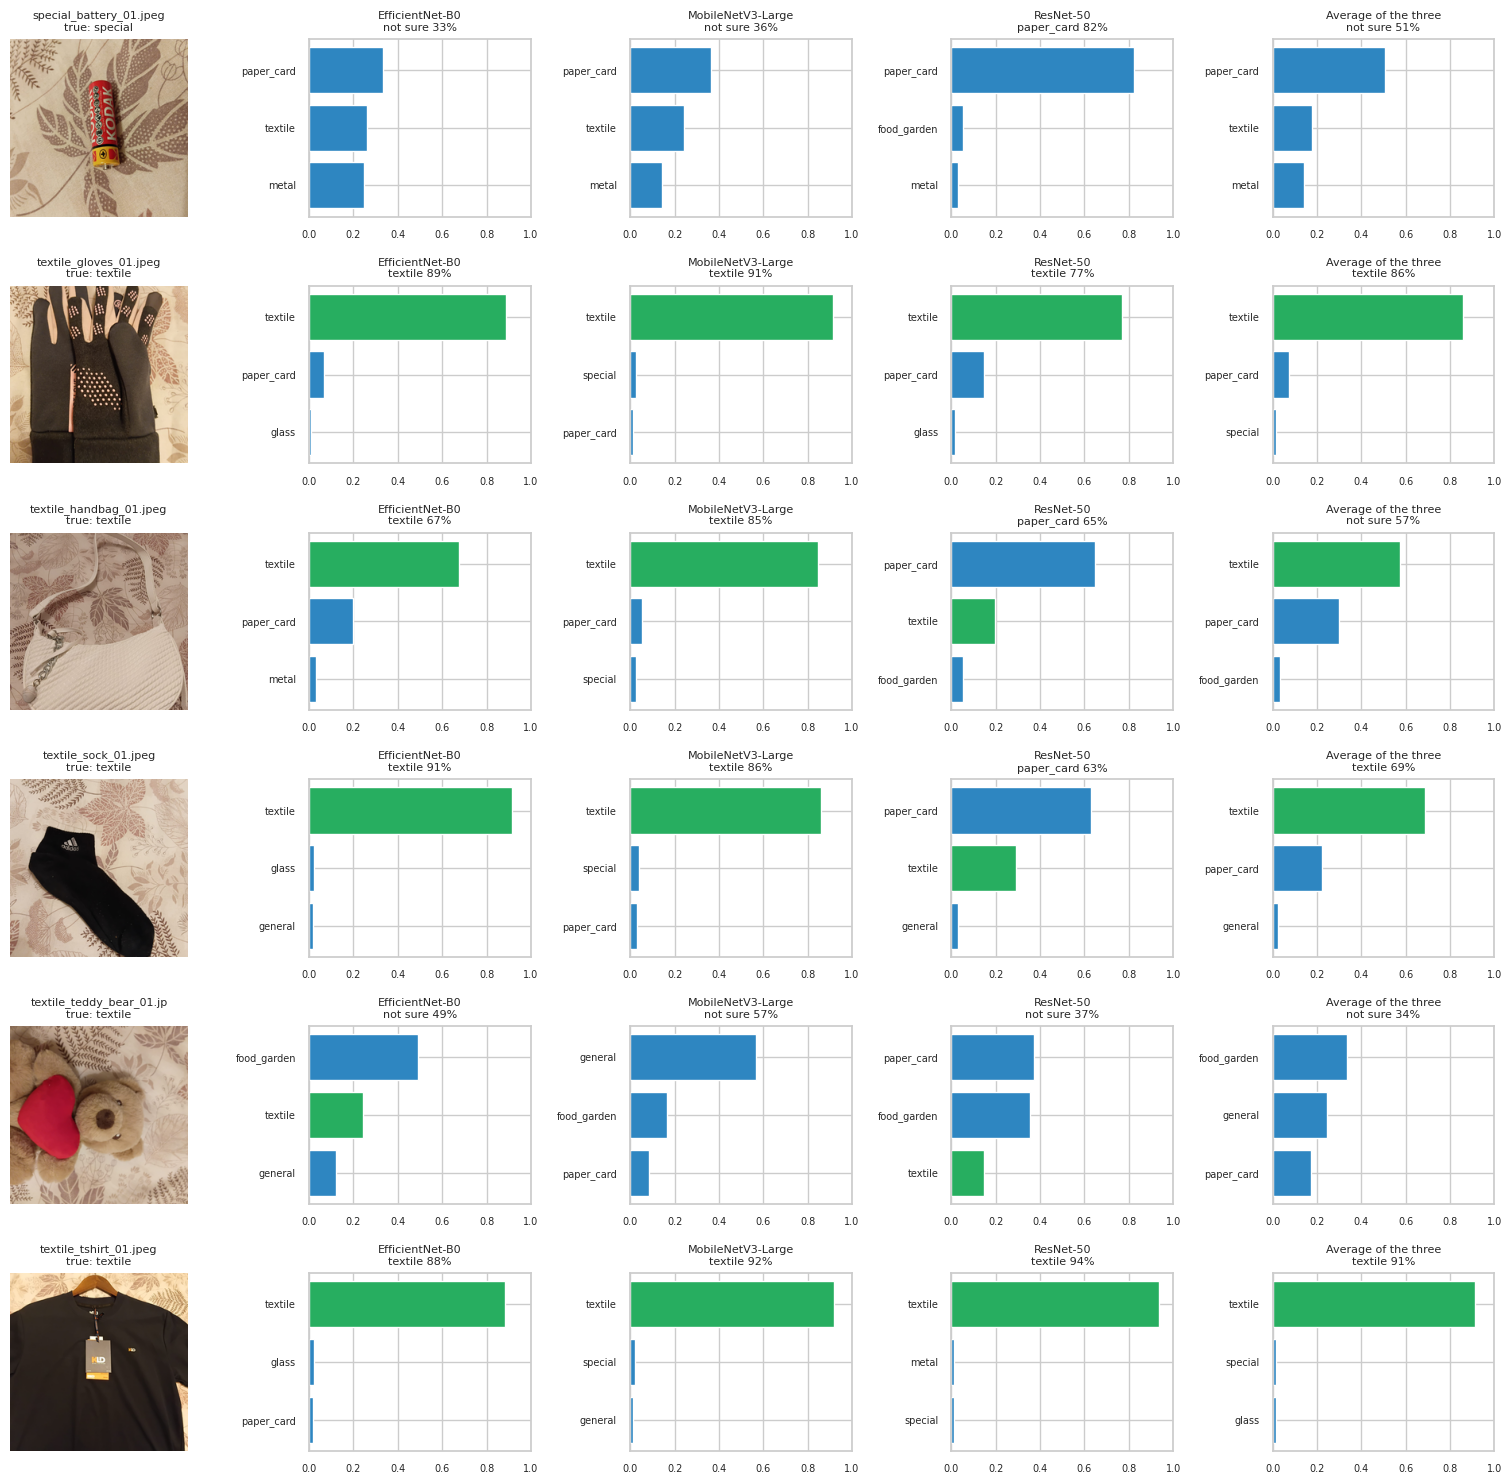

In [6]:
# WHAT: A table with one row per photo, then charts of each model's top-3 guesses, six
#       photos per figure.
# WHY:  Scores hide which items fail. This shows which photos are wrong, whether a wrong
#       answer is confident or "not sure", and where the models disagree.
# HOW:  An answer below 60% confidence is shown as "not sure", which is what the app shows. The
#       true class's bar is green. The note column marks a confident wrong answer of the average
#       with "WRONG!" and a photo where the three models do not give the same top answer with
#       "disagree".
# ------------------------------------------------------------------------------------

def answer(p):
    return class_names[p.argmax()] if p.max() >= THRESHOLD else "not sure"

table_p = pd.DataFrame({"photo": [n[:28] for n in photo_names],
                        "true": [class_names[i] if i >= 0 else "?" for i in y_photo]})
for k in ORDER:
    table_p[LABELS[k]] = [f"{answer(p)} {p.max():.0%}" for p in P[k]]
tops = np.stack([P[a].argmax(1) for a in (B0, MN, RN)])
disagree = ~(tops == tops[0]).all(0)
wrong_avg = (P["average"].argmax(1) != y_photo) & (P["average"].max(1) >= THRESHOLD) & scored
table_p["note"] = np.where(wrong_avg, "WRONG!", np.where(disagree, "disagree", ""))
pd.set_option("display.max_rows", 200)
display(table_p)

def gallery(idx):
    fig, axes = plt.subplots(len(idx), 1 + len(ORDER), figsize=(3.1 * (1 + len(ORDER)), 2.5 * len(idx)),
                             squeeze=False)
    for r, i in enumerate(idx):
        axes[r, 0].imshow(thumbs[i]); axes[r, 0].axis("off")
        axes[r, 0].set_title(f"{photo_names[i][:24]}\ntrue: {labels[i] or '?'}", fontsize=8)
        for c, k in enumerate(ORDER, 1):
            p = P[k][i]
            top = np.argsort(-p)[:3][::-1]
            ax = axes[r, c]
            ax.barh([class_names[j] for j in top], p[top],
                    color=["#27ae60" if j == y_photo[i] else "#2e86c1" for j in top])
            ax.set_xlim(0, 1)
            ax.tick_params(labelsize=7)
            ax.set_title(f"{LABELS[k]}\n{answer(p)} {p.max():.0%}", fontsize=8)
    plt.tight_layout(); plt.show()

for start in range(0, len(paths), 6):
    gallery(list(range(start, min(start + 6, len(paths)))))

**Finding:** Five photos are right for all three models: glass jug, cereal box, water bottle, gloves and t-shirt. The wipes pack is the only photo where every model, and the average, is confidently wrong (paper_card, 76-92%). All three models give the same top answer on 9 photos: 6 are right and 3 are wrong (keyboard, wipes pack, battery), so agreement does not mean correct. On the other 15 photos the top answers differ. B0's confident errors are mug -> plastic, hot water bottle -> glass, mouse -> metal, watch -> metal (94%), wipes -> paper_card and noodle wrapper -> textile. MobileNet's are keyboard, wipes and the white sheet (-> textile, 74%). Eight of ResNet-50's ten confident errors are "paper_card" (keyboard, mouse, watch, wipes, lip balm tin, battery, handbag, sock), all on the same beige patterned duvet, which suggests it is using the background; this is a hypothesis to test, not a result. The earlier hard items are still hard: the mouse and watch are wrong for every model that is confident, the wrapper is not right for any model, and the white sheet is right only for ResNet-50.

<a id="section-7"></a>
## Section 7: Classes and Hard Photos

**Goal:** See which classes the models find or miss, and which photos none of the three models gets right.

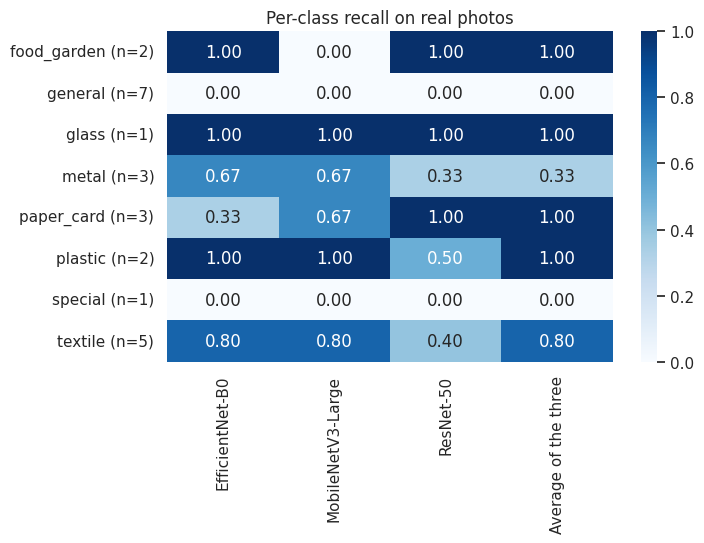

Photos that none of the three models gets right: 9 of 24


,photo,true class,most common wrong answer
0,general_ceramic_mug_01.jpeg,general,plastic
1,general_hot_water_bottle_01.jpeg,general,glass
2,general_keyboard_01.jpeg,general,paper_card
3,general_mouse_01.jpeg,general,metal
4,general_watch_01.jpeg,general,metal
5,general_wipes_pack_01.jpeg,general,paper_card
6,general_wrapper_noodles_01.jpeg,general,paper_card
7,special_battery_01.jpeg,special,paper_card
8,textile_teddy_bear_01.jpeg,textile,food_garden


In [7]:
# WHAT: Per-class recall for every model, and a list of photos that none of the three models
#       gets right.
# WHY:  Overall accuracy hides weak classes (the dataset showed electricals and mixed items
#       are hard). Photos that every model fails point to missing training data rather than a
#       bad model, and show what to photograph and train on next.
# HOW:  Recall = the share of a class's photos that a model gets right (top-1, any confidence).
#       Only classes that appear in the photos are shown, with their photo counts.
# ------------------------------------------------------------------------------------

if not HAVE_LABELS:
    print("No scored photos: skipped.")
else:
    y = y_photo[scored]
    counts = pd.Series([class_names[i] for i in y]).value_counts()
    recall = pd.DataFrame({LABELS[k]: [np.mean(P[k][scored].argmax(1)[y == c] == c) if (y == c).any() else np.nan
                                       for c in range(len(class_names))] for k in ORDER},
                          index=[f"{c} (n={counts.get(c, 0)})" for c in class_names])
    recall = recall.dropna(how="all")
    plt.figure(figsize=(7.5, 0.45 * len(recall) + 2))
    sns.heatmap(recall, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
    plt.title("Per-class recall on real photos")
    plt.tight_layout(); plt.show()

    none_right = np.all([P[a].argmax(1) != y_photo for a in (B0, MN, RN)], axis=0) & scored
    hard = []
    for i in np.where(none_right)[0]:
        guesses = pd.Series([class_names[P[a][i].argmax()] for a in (B0, MN, RN)])
        hard.append({"photo": photo_names[i], "true class": class_names[y_photo[i]],
                     "most common wrong answer": guesses.mode()[0]})
    print(f"Photos that none of the three models gets right: {len(hard)} of {scored.sum()}")
    if hard:
        display(pd.DataFrame(hard))

**Finding:** The weakest class is general: 0 of 7 for every model and for the average, and no model gave general more than about 20% on any of those photos, although its dataset recall is 0.83-0.85. special is 0 of 1 (the battery, called paper_card). Other classes are anecdotal with 1-3 photos each; textile (5 photos) is 4 of 5 for B0, MobileNet and the average, and 2 of 5 for ResNet-50. Nine photos are missed by all three models: mug, hot water bottle, keyboard, mouse, watch, wipes pack, noodle wrapper, battery and teddy bear. Seven are general, so electricals, film wrappers, ceramics, rubber, batteries and soft toys are what to photograph more of for fine-tuning.

<a id="section-8"></a>
## Section 8: Save and Summary

**Goal:** Save the tables for the logbook and the report, then record what was learned.

In [8]:
# WHAT: Save the per-photo table, the results table and a short summary file.
# WHY:  The numbers are needed for the logbook and the report, and the saved files stay with the
#       committed notebook, so the result can be reproduced and checked later.
# HOW:  CSV files in /kaggle/working; the summary records which models were used.
# ------------------------------------------------------------------------------------

table_p.to_csv(OUT / "real_photo_check_per_photo.csv", index=False)
if HAVE_LABELS:
    results.round(4).to_csv(OUT / "real_photo_check_results.csv")
json.dump({"models": {NAMES[a]: {"config": info[a]["config"], "seed": int(info[a]["seed"])} for a in nets},
           "photos": len(paths), "scored": int(scored.sum()), "threshold": THRESHOLD},
          open(OUT / "real_photo_check_summary.json", "w"), indent=2)
print("Saved: real_photo_check_per_photo.csv, real_photo_check_results.csv, real_photo_check_summary.json")

Saved: real_photo_check_per_photo.csv, real_photo_check_results.csv, real_photo_check_summary.json


**Summary:** The final models do not yet work on real photos: 93-95% on the dataset test set but 42-54% on 24 real photos, with 6 (B0), 3 (MobileNet) and 10 (ResNet-50) confident wrong answers. The average of the three is the safest (2 confident wrong) but gives a confident correct answer on only 7 photos and says "not sure" on 15, so it needs more than model averaging to be useful. general (0 of 7) and special (0 of 1) fail completely, and ResNet-50 should not be the deployed model. Next: Pi photos for fine-tuning with a held-out set, and plain-background retakes of the hard items to test whether the duvet is driving the errors.

**How to use the result**
1. Commit this notebook (Save & Run All) so the tables and charts exist as notebook output.
2. Use the dataset gap and the hard photos in the logbook and the report as the evidence for the real-world domain gap.
3. Photograph more of the failed items (electricals, batteries, wrappers, textiles) and keep them in two separate folders: fine-tuning photos and held-out test photos.

**Limitations**
- With about 24 photos, one photo is about 4 points of accuracy. This is a pilot check, not a score, and per-class numbers rest on one to three photos.
- The photos must not have been used for training or for choosing a model. If the models are later fine-tuned on these photos, repeat this check on new ones.
- Labels come from the file names, so a wrong file name is a wrong label.
- The 60% confidence threshold is fixed. A different threshold would change the "not sure" and "confident wrong" counts.
- The models were trained on the dataset, not on photos from our own camera, so a gap on electricals, batteries and wrappers shows missing data, not a failure of one network.
- Only the final model of each ablation notebook is used. Other seeds and configurations are covered by the earlier real-photo comparison notebook.

**Next steps:** fine-tune the chosen model on new fine-tuning photos and test on held-out photos; check the chosen model on the Raspberry Pi and the phone; link the "not sure" cases to the Llama clarifying question.